<a href="https://colab.research.google.com/github/ShreyasRamchandraDure/BIS_Lab/blob/main/ParticleSwarmOptimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Optimal Thresholds: [ 47 127 194]


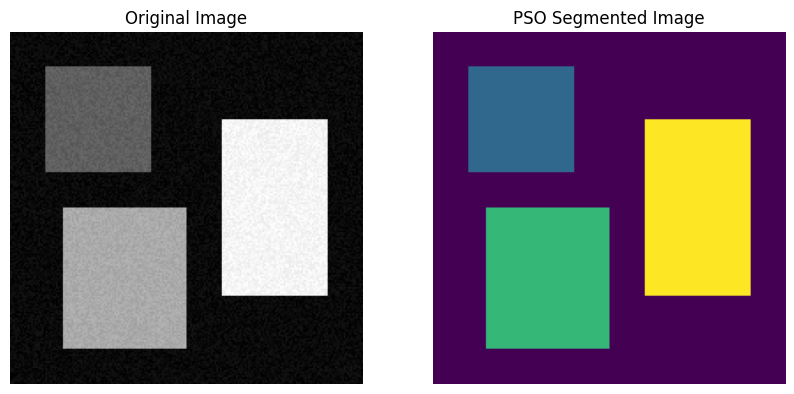

In [1]:

import numpy as np
import matplotlib.pyplot as plt

image = np.zeros((200, 200), dtype=np.uint8)

image[20:80, 20:80] = 80
image[100:180, 30:100] = 150
image[50:150, 120:180] = 220

noise = np.random.randint(0, 20, (200, 200))
image = np.clip(image + noise, 0, 255)

n_particles = 20
iterations = 50
w = 0.7
c1 = 1.5
c2 = 1.5
dimensions = 3

def fitness(thresholds):

    thresholds = np.sort(np.round(thresholds).astype(int))
    thresholds = np.clip(thresholds, 1, 254)

    hist, _ = np.histogram(image, bins=256, range=(0, 256))
    hist = hist / hist.sum()

    total_mean = np.sum(np.arange(256) * hist)

    boundaries = [0] + list(thresholds) + [256]

    variance = 0

    for i in range(4):
        a, b = boundaries[i], boundaries[i+1]

        weight = np.sum(hist[a:b])

        if weight == 0:
            continue

        mean = np.sum(np.arange(a, b) * hist[a:b]) / weight

        variance += weight * (mean - total_mean)**2

    return variance

position = np.random.uniform(
    20, 235, (n_particles, dimensions)
)

velocity = np.random.uniform(
    -5, 5, (n_particles, dimensions)
)

pbest = position.copy()
pbest_value = np.array([fitness(p) for p in position])

gbest = pbest[np.argmax(pbest_value)].copy()

for t in range(iterations):

    for i in range(n_particles):

        r1 = np.random.rand(dimensions)
        r2 = np.random.rand(dimensions)

        velocity[i] = (
            w * velocity[i]
            + c1 * r1 * (pbest[i] - position[i])
            + c2 * r2 * (gbest - position[i])
        )

        position[i] += velocity[i]
        position[i] = np.clip(position[i], 1, 254)

        value = fitness(position[i])

        if value > pbest_value[i]:
            pbest[i] = position[i].copy()
            pbest_value[i] = value

    gbest = pbest[np.argmax(pbest_value)].copy()


thresholds = np.sort(np.round(gbest).astype(int))

print("Optimal Thresholds:", thresholds)

segmented = np.digitize(image, thresholds)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(segmented, cmap='viridis')
plt.title("PSO Segmented Image")
plt.axis("off")

plt.show()
